### Time Series Analysis of Network Utilization for Distributed Scientific Workflows
#### Yingxin Deng
#### 2026/10/07

## Structured TCN: error propagation from access and hit to miss

The post-change-point Structured TCN predicts access and hit ratio, then reconstructs hit and miss so that `access = hit + miss` exactly. This diagnostic uses its saved held-out predictions; it does not retrain a model.

For each target, define `error = prediction - actual`. Because both predicted and actual values obey the identity, the miss error should satisfy:

\[e_{miss} = e_{access} - e_{hit}.\]

When access and hit errors have opposite signs, their magnitudes add in the implied miss error. We test this separately for count and size.

### 1. Load held-out Structured TCN predictions

These predictions come from the 14-day, five-block, 64-channel Structured TCN selected by validation hit-size RMSE in the post-change-point experiment.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

prediction_candidates = [
    Path('../week4/results/post_change_point_structured_14day_5block_64channel/predictions.csv'),
    Path('week4/results/post_change_point_structured_14day_5block_64channel/predictions.csv'),
]
prediction_file = next((path for path in prediction_candidates if path.is_file()), None)
if prediction_file is None:
    raise FileNotFoundError('Run the Week 4 post-change-point baseline first; predictions.csv was not found.')

predictions = pd.read_csv(prediction_file, index_col='target_date', parse_dates=True)
output_dir = Path.cwd() / 'results' / 'structured_error_propagation'
if not (Path.cwd() / 'Sammy_TCN_261007.ipynb').exists():
    output_dir = Path.cwd() / 'week5' / 'results' / 'structured_error_propagation'
output_dir.mkdir(parents=True, exist_ok=True)
print(f'Loaded {len(predictions)} held-out days: {predictions.index.min().date()} to {predictions.index.max().date()}')
print('Results will be saved to:', output_dir.resolve())


Loaded 96 held-out days: 2023-12-27 to 2024-03-31
Results will be saved to: /Users/dengyingxin/Desktop/xcache/week5/results/structured_error_propagation


### 2. Verify the identity and calculate daily errors

For each day, `access_error`, `hit_error`, and `miss_error` are measured in original units. The final column checks the theoretical relation `miss_error = access_error - hit_error`.

In [2]:
quantity_groups = {
    'count': ('access_count', 'hit_count', 'miss_count', 'requests'),
    'size': ('access_size', 'hit_size', 'miss_size', 'TB'),
}
error_frames = {}
identity_checks = []

for quantity, (access_name, hit_name, miss_name, unit) in quantity_groups.items():
    errors = pd.DataFrame(index=predictions.index)
    errors['access_error'] = predictions[f'{access_name}_predicted'] - predictions[f'{access_name}_actual']
    errors['hit_error'] = predictions[f'{hit_name}_predicted'] - predictions[f'{hit_name}_actual']
    errors['miss_error'] = predictions[f'{miss_name}_predicted'] - predictions[f'{miss_name}_actual']
    errors['error_identity_residual'] = errors['miss_error'] - (errors['access_error'] - errors['hit_error'])
    errors['opposite_sign'] = errors['access_error'] * errors['hit_error'] < 0
    error_frames[quantity] = errors
    identity_checks.append({
        'quantity': quantity,
        'unit': unit,
        'max_abs_prediction_identity_error': np.abs(predictions[f'{access_name}_predicted'] - predictions[f'{hit_name}_predicted'] - predictions[f'{miss_name}_predicted']).max(),
        'max_abs_error_identity_residual': np.abs(errors['error_identity_residual']).max(),
    })

identity_check_table = pd.DataFrame(identity_checks)
display(identity_check_table)
identity_check_table.to_csv(output_dir / 'identity_checks.csv', index=False)


,quantity,unit,max_abs_prediction_identity_error,max_abs_error_identity_residual
0,count,requests,4.320100e-12,7.275958e-12
1,size,TB,9.769963e-15,7.000000e-06


### 3. Compare miss error when access and hit errors agree or disagree

`Opposite-sign` means access and hit are wrong in opposite directions. In this case, the identity implies their errors add in the miss estimate. `Same-sign or zero` is the comparison group.

In [3]:
propagation_rows = []
for quantity, (_, _, _, unit) in quantity_groups.items():
    errors = error_frames[quantity]
    for label, mask in {
        'Opposite-sign access/hit errors': errors['opposite_sign'],
        'Same-sign or zero access/hit errors': ~errors['opposite_sign'],
    }.items():
        miss_error = errors.loc[mask, 'miss_error']
        propagation_rows.append({
            'quantity': quantity, 'error relationship': label, 'days': int(mask.sum()), 'unit': unit,
            'miss MAE': np.abs(miss_error).mean(),
            'miss RMSE': np.sqrt(np.mean(miss_error ** 2)),
            'mean absolute access error': np.abs(errors.loc[mask, 'access_error']).mean(),
            'mean absolute hit error': np.abs(errors.loc[mask, 'hit_error']).mean(),
        })

propagation_summary = pd.DataFrame(propagation_rows)
display(propagation_summary)
propagation_summary.to_csv(output_dir / 'opposite_vs_same_sign_miss_error.csv', index=False)


,quantity,error relationship,days,unit,miss MAE,miss RMSE,mean absolute access error,mean absolute hit error
0,count,Opposite-sign access/hit errors,1,requests,486.237573,486.237573,388.825123,97.412450
1,count,Same-sign or zero access/hit errors,95,requests,865.086529,1267.153657,9577.337079,8861.406368
2,size,Opposite-sign access/hit errors,3,TB,1.656245,1.721035,0.502629,1.153616
3,size,Same-sign or zero access/hit errors,93,TB,1.527379,1.722353,21.329407,20.696649


### 4. Visualize error propagation

Each point is one held-out day. The x-axis is access error and the y-axis is hit error. Color shows absolute miss error. The upper-left and lower-right quadrants contain opposite-sign errors, where miss error can be amplified. Count and size use separate panels because they have different units.

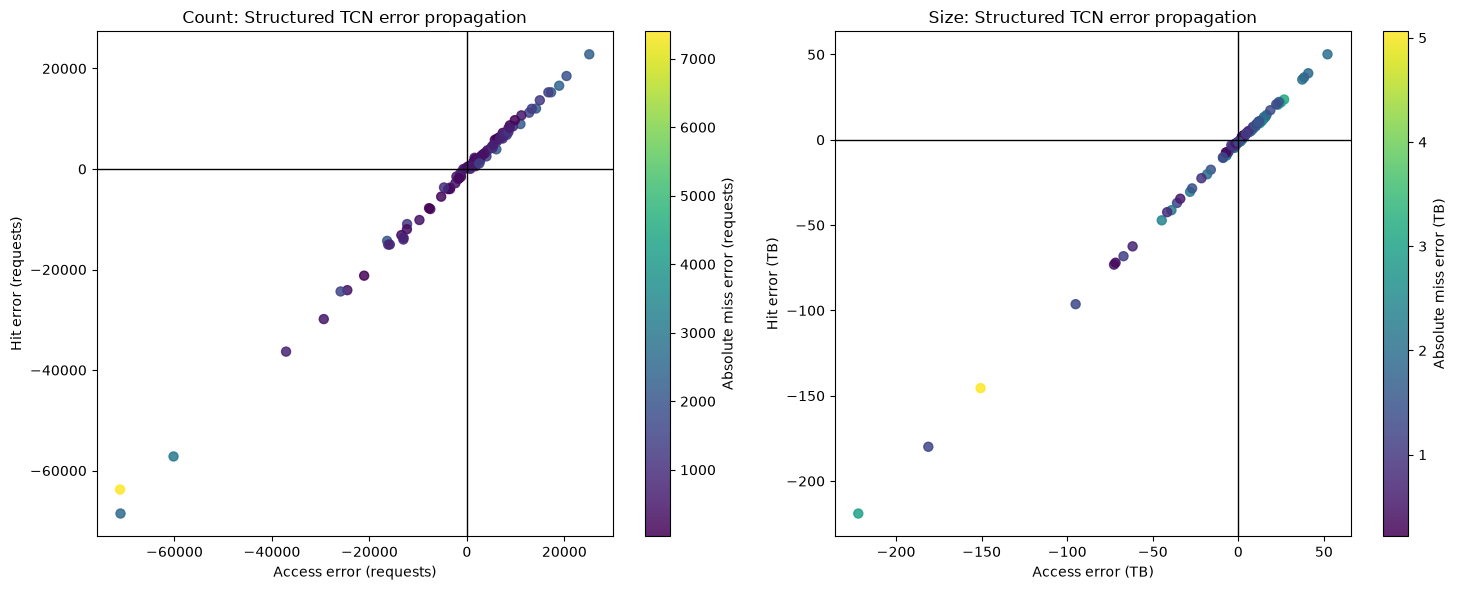

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for axis, (quantity, (_, _, _, unit)) in zip(axes, quantity_groups.items()):
    errors = error_frames[quantity]
    scatter = axis.scatter(errors['access_error'], errors['hit_error'], c=np.abs(errors['miss_error']), cmap='viridis', s=42, alpha=0.85)
    axis.axhline(0, color='black', linewidth=1)
    axis.axvline(0, color='black', linewidth=1)
    axis.set(title=f'{quantity.title()}: Structured TCN error propagation', xlabel=f'Access error ({unit})', ylabel=f'Hit error ({unit})')
    colorbar = fig.colorbar(scatter, ax=axis)
    colorbar.set_label(f'Absolute miss error ({unit})')
fig.tight_layout()
fig.savefig(output_dir / 'access_hit_error_vs_miss_error.png', dpi=200, bbox_inches='tight')
plt.show()


### 5. Inspect the largest opposite-sign miss errors

These dates provide concrete examples for the analysis and can be compared with the original access, hit, and miss trajectories.

In [5]:
for quantity, (access_name, hit_name, miss_name, unit) in quantity_groups.items():
    examples = error_frames[quantity].loc[error_frames[quantity]['opposite_sign']].copy()
    examples['absolute_miss_error'] = np.abs(examples['miss_error'])
    examples = examples.join(predictions[[f'{access_name}_actual', f'{access_name}_predicted', f'{hit_name}_actual', f'{hit_name}_predicted', f'{miss_name}_actual', f'{miss_name}_predicted']])
    examples = examples.sort_values('absolute_miss_error', ascending=False).head(10)
    print(f'\nLargest opposite-sign {quantity} cases ({unit}):')
    display(examples)
    examples.to_csv(output_dir / f'largest_opposite_sign_{quantity}_examples.csv')



Largest opposite-sign count cases (requests):


,access_error,hit_error,miss_error,error_identity_residual,opposite_sign,absolute_miss_error,access_count_actual,access_count_predicted,hit_count_actual,hit_count_predicted,miss_count_actual,miss_count_predicted
target_date,,,,,,,,,,,,
2024-02-04,-388.825123,97.41245,-486.237573,0.0,True,486.237573,14491.0,14102.174877,12304.0,12401.41245,2187.0,1700.762427



Largest opposite-sign size cases (TB):


,access_error,hit_error,miss_error,error_identity_residual,opposite_sign,absolute_miss_error,access_size_actual,access_size_predicted,hit_size_actual,hit_size_predicted,miss_size_actual,miss_size_predicted
target_date,,,,,,,,,,,,
2024-01-14,1.400444,-0.915043,2.315486,-3.100000e-07,True,2.315486,16.630170,18.030614,16.482904,15.567861,0.147266,2.462752
2024-03-21,0.086401,-1.287886,1.374290,2.960000e-06,True,1.374290,61.881355,61.967756,61.168434,59.880548,0.712918,2.087208
2024-03-07,0.021041,-1.257918,1.278959,1.800000e-07,True,1.278959,27.646568,27.667609,27.522594,26.264676,0.123974,1.402933


## 6. Decompose Structured TCN miss error into access and hit-ratio contributions

The Structured TCN does not predict hit directly; it predicts access `A` and hit ratio `r`, then reconstructs `miss = A(1-r)`. Therefore, the relevant miss-error decomposition is:

\[e_{miss} = (1-r)e_{access} - \hat{A}e_r,\]

where `e_access = A_hat - A` and `e_r = r_hat - r`. The first term is the access contribution; the second is the hit-ratio contribution. This analysis identifies which term dominates miss error on each held-out day.

In [6]:
# Required first: run Sections 1 and 2 to load predictions and define quantity_groups.
decomposition_frames = {}
decomposition_rows = []

for quantity, (access_name, hit_name, miss_name, unit) in quantity_groups.items():
    actual_access = predictions[f'{access_name}_actual'].to_numpy()
    predicted_access = predictions[f'{access_name}_predicted'].to_numpy()
    actual_hit = predictions[f'{hit_name}_actual'].to_numpy()
    predicted_hit = predictions[f'{hit_name}_predicted'].to_numpy()
    actual_miss = predictions[f'{miss_name}_actual'].to_numpy()
    predicted_miss = predictions[f'{miss_name}_predicted'].to_numpy()

    actual_ratio = np.divide(actual_hit, actual_access, out=np.zeros_like(actual_hit), where=actual_access > 0)
    predicted_ratio = np.divide(predicted_hit, predicted_access, out=np.zeros_like(predicted_hit), where=predicted_access > 0)
    access_error = predicted_access - actual_access
    ratio_error = predicted_ratio - actual_ratio
    miss_error = predicted_miss - actual_miss
    access_contribution = (1 - actual_ratio) * access_error
    ratio_contribution = -predicted_access * ratio_error

    decomposition = pd.DataFrame({
        'actual_access': actual_access, 'predicted_access': predicted_access,
        'actual_ratio': actual_ratio, 'predicted_ratio': predicted_ratio,
        'access_error': access_error, 'ratio_error': ratio_error, 'miss_error': miss_error,
        'access_contribution': access_contribution, 'ratio_contribution': ratio_contribution,
    }, index=predictions.index)
    decomposition['reconstruction_residual'] = decomposition['miss_error'] - decomposition['access_contribution'] - decomposition['ratio_contribution']
    decomposition['dominant_source'] = np.where(np.abs(decomposition['ratio_contribution']) > np.abs(decomposition['access_contribution']), 'Ratio-dominated', 'Access-dominated')
    decomposition_frames[quantity] = decomposition

    for source, rows in decomposition.groupby('dominant_source'):
        decomposition_rows.append({
            'quantity': quantity, 'dominant source': source, 'days': len(rows), 'unit': unit,
            'miss MAE': np.abs(rows['miss_error']).mean(),
            'miss RMSE': np.sqrt(np.mean(rows['miss_error'] ** 2)),
            'mean absolute access contribution': np.abs(rows['access_contribution']).mean(),
            'mean absolute ratio contribution': np.abs(rows['ratio_contribution']).mean(),
            'max absolute reconstruction residual': np.abs(rows['reconstruction_residual']).max(),
        })

decomposition_summary = pd.DataFrame(decomposition_rows)
display(decomposition_summary)
decomposition_summary.to_csv(output_dir / 'miss_error_decomposition_summary.csv', index=False)
for quantity, decomposition in decomposition_frames.items():
    decomposition.to_csv(output_dir / f'{quantity}_miss_error_decomposition.csv', index_label='target_date')


,quantity,dominant source,days,unit,miss MAE,miss RMSE,mean absolute access contribution,mean absolute ratio contribution,max absolute reconstruction residual
0,count,Access-dominated,34,requests,1065.983029,1697.659074,1979.702411,1035.475459,4.035883e-12
1,count,Ratio-dominated,62,requests,748.807014,940.026584,213.127855,737.082698,5.456968e-12
2,size,Access-dominated,8,TB,2.133941,2.501228,3.267871,1.240180,7.000000e-06
3,size,Ratio-dominated,88,TB,1.476631,1.633183,0.115527,1.471037,6.450000e-06


### 7. Visualize access and ratio contributions

Each point is one test day. Both axes are contributions to miss error in the original unit. Days far from the vertical axis are driven mainly by access error; days far from the horizontal axis are driven mainly by hit-ratio error. Color shows absolute miss error.

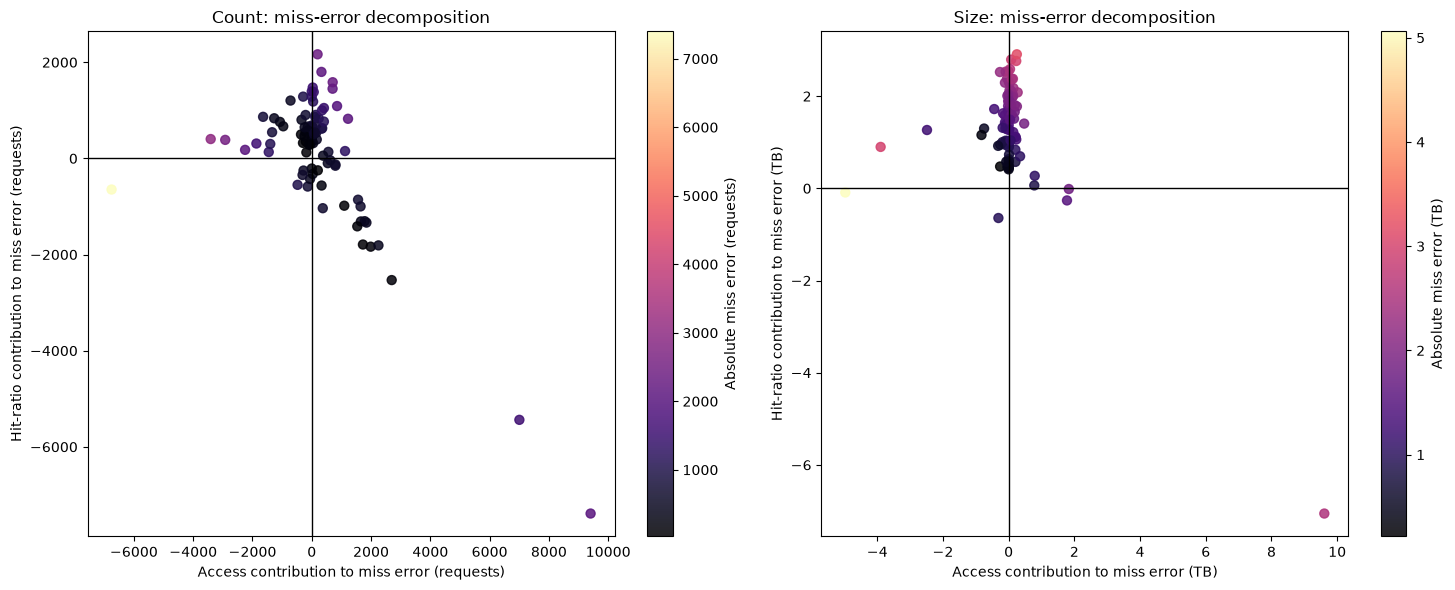


Largest ratio-dominated count miss-error cases:


,actual_access,predicted_access,actual_ratio,predicted_ratio,access_error,ratio_error,miss_error,access_contribution,ratio_contribution,reconstruction_residual,dominant_source,absolute_miss_error
target_date,,,,,,,,,,,,
2024-02-10,8578.0,27516.816805,0.989625,0.910909,18938.816805,-0.078716,2362.510648,196.497400,2166.013248,-4.547474e-13,Ratio-dominated,2362.510648
2024-03-27,17751.0,42865.391650,0.971889,0.934914,25114.391650,-0.036975,2290.942296,705.992983,1584.949313,4.547474e-12,Ratio-dominated,2290.942296
2024-01-19,9229.0,23414.409665,0.950482,0.888541,14185.409665,-0.061941,2152.740102,702.430623,1450.309479,-2.501110e-12,Ratio-dominated,2152.740102
2024-01-01,5332.0,11381.438395,0.945986,0.787866,6049.438395,-0.158120,2126.386702,326.751361,1799.635341,-1.591616e-12,Ratio-dominated,2126.386702
2024-03-22,3353.0,23799.023892,0.958246,0.912493,20446.023892,-0.045753,1942.582829,853.696196,1088.886633,0.000000e+00,Ratio-dominated,1942.582829
2024-02-16,16371.0,20396.152416,0.991998,0.919720,4025.152416,-0.072278,1506.409315,32.209087,1474.200228,-5.456968e-12,Ratio-dominated,1506.409315
2024-03-31,7821.0,24539.621375,0.975451,0.932721,16718.621375,-0.042730,1459.009501,410.430291,1048.579211,-2.728484e-12,Ratio-dominated,1459.009501
2024-03-30,29068.0,31631.942639,0.973854,0.930176,2563.942639,-0.043678,1448.653057,67.035792,1381.617265,1.136868e-12,Ratio-dominated,1448.653057
2024-01-27,1363.0,9543.719551,1.000000,0.853988,8180.719551,-0.146012,1393.501639,0.000000,1393.501639,0.000000e+00,Ratio-dominated,1393.501639



Largest ratio-dominated size miss-error cases:


,actual_access,predicted_access,actual_ratio,predicted_ratio,access_error,ratio_error,miss_error,access_contribution,ratio_contribution,reconstruction_residual,dominant_source,absolute_miss_error
target_date,,,,,,,,,,,,
2024-02-03,7.689738,34.466607,0.990676,0.906278,26.776868,-0.084398,3.158591,0.249665,2.908926,2.800000e-07,Ratio-dominated,3.158591
2024-01-19,20.441628,45.238644,0.990686,0.929601,24.797016,-0.061085,2.994373,0.230953,2.763419,5.400000e-07,Ratio-dominated,2.994373
2024-01-15,10.223942,22.840756,0.993986,0.871678,12.616814,-0.122309,2.869497,0.075876,2.793621,-1.900000e-07,Ratio-dominated,2.869497
2024-01-16,12.009532,25.777111,0.996976,0.896598,13.767579,-0.100378,2.629084,0.041626,2.587457,2.860000e-07,Ratio-dominated,2.629084
2024-01-12,16.357468,14.128027,0.996158,0.816153,-2.229441,-0.180005,2.534552,-0.008565,2.543117,-5.500000e-07,Ratio-dominated,2.534552
2023-12-30,5.082724,20.265463,0.991441,0.874153,15.182739,-0.117288,2.506849,0.129950,2.376899,-2.000001e-08,Ratio-dominated,2.506849
2024-02-07,15.719316,29.478237,0.992829,0.912286,13.758921,-0.080543,2.472931,0.098669,2.374263,-3.000000e-08,Ratio-dominated,2.472931
2024-02-08,70.416060,25.673402,0.997968,0.899349,-44.742658,-0.098619,2.440951,-0.090926,2.531879,-1.570000e-06,Ratio-dominated,2.440951
2023-12-27,2.506112,18.371957,0.982701,0.869346,15.865846,-0.113356,2.357019,0.274456,2.082563,-2.250000e-07,Ratio-dominated,2.357019


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for axis, (quantity, (_, _, _, unit)) in zip(axes, quantity_groups.items()):
    decomposition = decomposition_frames[quantity]
    scatter = axis.scatter(decomposition['access_contribution'], decomposition['ratio_contribution'], c=np.abs(decomposition['miss_error']), cmap='magma', s=42, alpha=0.85)
    axis.axhline(0, color='black', linewidth=1)
    axis.axvline(0, color='black', linewidth=1)
    axis.set(title=f'{quantity.title()}: miss-error decomposition', xlabel=f'Access contribution to miss error ({unit})', ylabel=f'Hit-ratio contribution to miss error ({unit})')
    colorbar = fig.colorbar(scatter, ax=axis)
    colorbar.set_label(f'Absolute miss error ({unit})')
fig.tight_layout()
fig.savefig(output_dir / 'miss_error_decomposition_scatter.png', dpi=200, bbox_inches='tight')
plt.show()

for quantity, decomposition in decomposition_frames.items():
    print(f'\nLargest ratio-dominated {quantity} miss-error cases:')
    examples = decomposition.loc[decomposition['dominant_source'] == 'Ratio-dominated'].copy()
    examples['absolute_miss_error'] = np.abs(examples['miss_error'])
    display(examples.sort_values('absolute_miss_error', ascending=False).head(10))


## 8. Soft-constrained multi-task TCN

This model uses all six observed variables as input and directly predicts all six next-day variables. Unlike the current Structured TCN, miss has its own prediction target and can learn independent temporal patterns. Non-negativity is enforced when converting predicted log values back to original units.

The training loss is:

\[L=L_{six-variable\ MSE}+\lambda L_{identity},\qquad L_{identity}=\frac{1}{2}\sum_{q\in\{count,size\}}\left(\frac{\hat A_q-\hat H_q-\hat M_q}{s_{A,q}}\right)^2.\]

The identity residual is normalized by the training-period standard deviation of access in each unit, so count and size contribute comparably. This first experiment fixes `lambda = 1.0`; it should later be compared with `lambda = 0` and other weights.

In [8]:
# This cell is self-contained. It uses the same post-change-point split and TCN capacity as Week 4.
from pathlib import Path
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED, LOOKBACK = 42, 14
FEATURE_NAMES = ['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count', 'miss_size']
CHANNELS, KERNEL_SIZE, DROPOUT = (64, 64, 64, 64, 64), 3, 0.1
MAX_EPOCHS, PATIENCE, BATCH_SIZE, LEARNING_RATE = 60, 10, 32, 1e-3
IDENTITY_WEIGHT = 1.0
PRIMARY_SELECTION_INDEX = FEATURE_NAMES.index('hit_size')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

data_dirs = [Path('../xcache-ts-df'), Path('../xcache-ts/pickled_data/df'), Path('xcache-ts-df'), Path('xcache-ts/pickled_data/df')]
data_file = next((directory / 'socal-2006-2403-daily-ml' for directory in data_dirs if (directory / 'socal-2006-2403-daily-ml').is_file()), None)
if data_file is None: raise FileNotFoundError('Cannot find the SoCal daily data file.')
multitask_df = pd.read_pickle(data_file).loc['2022-07-01':'2024-03-31', FEATURE_NAMES].copy()
multitask_df[['access_size', 'hit_size', 'miss_size']] /= 1000 ** 4
assert len(multitask_df) == 640

n_days, train_end, validation_end = len(multitask_df), 448, 544
raw_values = multitask_df.to_numpy(dtype=np.float32)
log_values = np.log1p(raw_values).astype(np.float32)
log_scaler = StandardScaler().fit(log_values[:train_end])
scaled_values = log_scaler.transform(log_values).astype(np.float32)
positions = np.arange(LOOKBACK, n_days)
features = np.asarray([scaled_values[position - LOOKBACK:position] for position in positions], dtype=np.float32)
labels = scaled_values[positions]
train_mask = positions < train_end
validation_mask = (positions >= train_end) & (positions < validation_end)
test_mask = positions >= validation_end

class Chomp1d(nn.Module):
    def __init__(self, size): super().__init__(); self.size = size
    def forward(self, x): return x[:, :, :-self.size].contiguous() if self.size else x

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dilation):
        super().__init__(); padding = (KERNEL_SIZE - 1) * dilation
        self.net = nn.Sequential(nn.Conv1d(in_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation), Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT), nn.Conv1d(out_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation), Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT))
        self.residual = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()
    def forward(self, x): return torch.relu(self.net(x) + self.residual(x))

class SoftConstrainedMultiTaskTCN(nn.Module):
    def __init__(self):
        super().__init__(); blocks, in_channels = [], len(FEATURE_NAMES)
        for level, out_channels in enumerate(CHANNELS):
            blocks.append(TemporalBlock(in_channels, out_channels, 2 ** level)); in_channels = out_channels
        self.tcn = nn.Sequential(*blocks)
        self.output = nn.Linear(CHANNELS[-1], len(FEATURE_NAMES))
    def forward(self, x): return self.output(self.tcn(x)[:, :, -1])

log_mean = torch.tensor(log_scaler.mean_.tolist(), dtype=torch.float32, device=device)
log_scale = torch.tensor(log_scaler.scale_.tolist(), dtype=torch.float32, device=device)
identity_scale = torch.tensor(np.std(raw_values[:train_end, [0, 1]], axis=0).tolist(), dtype=torch.float32, device=device)

def decode_original(prediction_standardized):
    decoded_log = prediction_standardized * log_scale + log_mean
    return torch.clamp(torch.expm1(decoded_log), min=0)

def multitask_loss(prediction_standardized, target_standardized):
    prediction_loss = nn.functional.mse_loss(prediction_standardized, target_standardized)
    prediction_original = decode_original(prediction_standardized)
    count_identity = (prediction_original[:, 0] - prediction_original[:, 2] - prediction_original[:, 4]) / identity_scale[0]
    size_identity = (prediction_original[:, 1] - prediction_original[:, 3] - prediction_original[:, 5]) / identity_scale[1]
    identity_loss = 0.5 * (torch.mean(count_identity ** 2) + torch.mean(size_identity ** 2))
    return prediction_loss + IDENTITY_WEIGHT * identity_loss, prediction_loss, identity_loss

def make_loader(x, y, shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(x.transpose(0, 2, 1).tolist(), dtype=torch.float32), torch.tensor(y.tolist(), dtype=torch.float32)), batch_size=BATCH_SIZE, shuffle=shuffle)

def predict_original(model_run, x):
    model_run.eval(); outputs = []
    with torch.no_grad():
        for start in range(0, len(x), BATCH_SIZE):
            tensor = torch.tensor(x[start:start + BATCH_SIZE].transpose(0, 2, 1).tolist(), dtype=torch.float32).to(device)
            outputs.append(decode_original(model_run(tensor)).cpu().tolist())
    return np.asarray([row for batch in outputs for row in batch], dtype=np.float64)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
model = SoftConstrainedMultiTaskTCN().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
train_loader = make_loader(features[train_mask], labels[train_mask], shuffle=True)
validation_actual = raw_values[positions[validation_mask]]
best_rmse, best_state, best_epoch, stale, history_rows = float('inf'), None, 0, 0, []

for epoch in range(1, MAX_EPOCHS + 1):
    model.train(); total_losses, prediction_losses, identity_losses = [], [], []
    for xb, yb in train_loader:
        optimizer.zero_grad()
        total_loss, prediction_loss, identity_loss = multitask_loss(model(xb.to(device)), yb.to(device))
        total_loss.backward(); optimizer.step()
        total_losses.append(total_loss.item()); prediction_losses.append(prediction_loss.item()); identity_losses.append(identity_loss.item())
    validation_prediction = predict_original(model, features[validation_mask])
    validation_rmse = float(np.sqrt(np.mean((validation_prediction[:, PRIMARY_SELECTION_INDEX] - validation_actual[:, PRIMARY_SELECTION_INDEX]) ** 2)))
    history_rows.append({'epoch': epoch, 'training_total_loss': np.mean(total_losses), 'training_prediction_loss': np.mean(prediction_losses), 'training_identity_loss': np.mean(identity_losses), 'validation_hit_size_rmse': validation_rmse})
    if validation_rmse < best_rmse:
        best_rmse, best_state, best_epoch, stale = validation_rmse, copy.deepcopy(model.state_dict()), epoch, 0
    else:
        stale += 1
    if stale >= PATIENCE: break

model.load_state_dict(best_state)
history = pd.DataFrame(history_rows)
print(f'Selected epoch: {best_epoch}; validation hit_size RMSE: {best_rmse:.4f} TB')



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/traitlets/config/application.py", line 1082, in launch_instance
    app.start()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipyk

Selected epoch: 2; validation hit_size RMSE: 19.2169 TB


### 9. Evaluate the held-out test period

The checkpoint remains selected by validation hit-size RMSE. Test RMSE, persistence RMSE, and identity error are reported in original units.

In [9]:
test_prediction = predict_original(model, features[test_mask])
test_actual = raw_values[positions[test_mask]]
persistence = raw_values[positions[test_mask] - 1]
test_rmse = np.sqrt(np.mean((test_prediction - test_actual) ** 2, axis=0))
persistence_rmse = np.sqrt(np.mean((persistence - test_actual) ** 2, axis=0))

test_identity_error = {
    'count': np.abs(test_prediction[:, 0] - test_prediction[:, 2] - test_prediction[:, 4]),
    'size': np.abs(test_prediction[:, 1] - test_prediction[:, 3] - test_prediction[:, 5]),
}
results = pd.DataFrame({
    'Soft-constrained multi-task TCN RMSE': test_rmse,
    'Persistence RMSE': persistence_rmse,
    'Improvement over persistence (%)': 100 * (1 - test_rmse / persistence_rmse),
    'Unit': ['requests' if 'count' in name else 'TB' for name in FEATURE_NAMES],
}, index=FEATURE_NAMES)
display(results)
print('Mean absolute identity error — count:', test_identity_error['count'].mean(), 'requests')
print('Mean absolute identity error — size:', test_identity_error['size'].mean(), 'TB')

week5_dir = Path.cwd() if (Path.cwd() / 'Sammy_TCN_261007.ipynb').exists() else Path.cwd() / 'week5'
multitask_output_dir = week5_dir / 'results' / 'soft_constrained_multitask_tcn_lambda_1'
multitask_output_dir.mkdir(parents=True, exist_ok=True)
history.to_csv(multitask_output_dir / 'history.csv', index=False)
results.to_csv(multitask_output_dir / 'test_rmse.csv')
pd.DataFrame({'count_identity_error': test_identity_error['count'], 'size_identity_error': test_identity_error['size']}, index=multitask_df.index[positions[test_mask]]).to_csv(multitask_output_dir / 'identity_errors.csv', index_label='target_date')
predictions_out = pd.DataFrame(index=multitask_df.index[positions[test_mask]]); predictions_out.index.name = 'target_date'
for i, name in enumerate(FEATURE_NAMES):
    predictions_out[f'{name}_actual'] = test_actual[:, i]
    predictions_out[f'{name}_predicted'] = test_prediction[:, i]
    predictions_out[f'{name}_persistence'] = persistence[:, i]
predictions_out.to_csv(multitask_output_dir / 'predictions.csv')
print('Saved results to:', multitask_output_dir.resolve())


,Soft-constrained multi-task TCN RMSE,Persistence RMSE,Improvement over persistence (%),Unit
access_count,16671.475826,19116.796875,12.791479,requests
access_size,41.874680,47.844620,12.477767,TB
hit_count,15849.892621,17914.582031,11.525189,requests
hit_size,41.061203,47.000496,12.636660,TB
miss_count,1366.317171,1482.898804,7.861739,requests
miss_size,0.995876,1.156154,13.863072,TB


Mean absolute identity error — count: 1447.0552311142285 requests
Mean absolute identity error — size: 2.0461182316454747 TB
Saved results to: /Users/dengyingxin/Desktop/xcache/week5/results/soft_constrained_multitask_tcn_lambda_1


### 10. Compare hard and soft identity constraints

This comparison uses the same post-change-point held-out test dates. The hard-constrained Structured TCN reconstructs miss exactly; the soft-constrained multi-task TCN learns miss directly and allows a nonzero identity residual.

In [10]:
structured_result_candidates = [
    Path('../week4/results/post_change_point_structured_14day_5block_64channel/test_rmse.csv'),
    Path('week4/results/post_change_point_structured_14day_5block_64channel/test_rmse.csv'),
]
structured_result_file = next((path for path in structured_result_candidates if path.is_file()), None)
if structured_result_file is None: raise FileNotFoundError('Week 4 Structured TCN test_rmse.csv was not found.')
hard_results = pd.read_csv(structured_result_file, index_col=0)
constraint_comparison = pd.DataFrame({
    'Hard-constrained Structured TCN RMSE': hard_results['Structured TCN RMSE'],
    'Soft-constrained multi-task TCN RMSE': results['Soft-constrained multi-task TCN RMSE'],
    'Persistence RMSE': results['Persistence RMSE'],
    'Unit': results['Unit'],
}, index=FEATURE_NAMES)
constraint_comparison['Soft minus hard RMSE'] = constraint_comparison['Soft-constrained multi-task TCN RMSE'] - constraint_comparison['Hard-constrained Structured TCN RMSE']
display(constraint_comparison)
constraint_comparison.to_csv(multitask_output_dir / 'hard_vs_soft_constraint_comparison.csv')
print('A negative Soft minus hard RMSE means the soft-constrained model is better for that variable.')


,Hard-constrained Structured TCN RMSE,Soft-constrained multi-task TCN RMSE,Persistence RMSE,Unit,Soft minus hard RMSE
access_count,15799.924121,16671.475826,19116.796875,requests,871.551705
access_size,40.534954,41.874680,47.844620,TB,1.339725
hit_count,14847.777690,15849.892621,17914.582031,requests,1002.114931
hit_size,40.039870,41.061203,47.000496,TB,1.021333
miss_count,1261.513121,1366.317171,1482.898804,requests,104.804050
miss_size,1.722312,0.995876,1.156154,TB,-0.726436


A negative Soft minus hard RMSE means the soft-constrained model is better for that variable.


## 11. Identity-weight scan

This experiment holds the multi-task architecture, log transformation, input variables, data split, seed, optimizer, and checkpoint-selection metric fixed. It changes only the soft identity weight `lambda`. `lambda = 0` is an unconstrained six-variable multi-task TCN; larger values increasingly penalize violations of `access = hit + miss`.

All models are selected by validation hit-size RMSE. The test set is used only for the final comparison.

In [11]:
# Required first: run Section 8 to define the data, model class, and helper functions.
IDENTITY_WEIGHTS = [0.0, 0.1, 1.0, 5.0]

def loss_with_identity_weight(prediction_standardized, target_standardized, identity_weight):
    prediction_loss = nn.functional.mse_loss(prediction_standardized, target_standardized)
    prediction_original = decode_original(prediction_standardized)
    count_identity = (prediction_original[:, 0] - prediction_original[:, 2] - prediction_original[:, 4]) / identity_scale[0]
    size_identity = (prediction_original[:, 1] - prediction_original[:, 3] - prediction_original[:, 5]) / identity_scale[1]
    identity_loss = 0.5 * (torch.mean(count_identity ** 2) + torch.mean(size_identity ** 2))
    return prediction_loss + identity_weight * identity_loss, prediction_loss, identity_loss

def run_identity_weight(identity_weight):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    model_run = SoftConstrainedMultiTaskTCN().to(device)
    optimizer_run = torch.optim.Adam(model_run.parameters(), lr=LEARNING_RATE)
    train_loader_run = make_loader(features[train_mask], labels[train_mask], shuffle=True)
    best_rmse_run, best_state_run, best_epoch_run, stale_run = float('inf'), None, 0, 0
    history_run = []
    for epoch in range(1, MAX_EPOCHS + 1):
        model_run.train(); total_losses, prediction_losses, identity_losses = [], [], []
        for xb, yb in train_loader_run:
            optimizer_run.zero_grad()
            total_loss, prediction_loss, identity_loss = loss_with_identity_weight(model_run(xb.to(device)), yb.to(device), identity_weight)
            total_loss.backward(); optimizer_run.step()
            total_losses.append(total_loss.item()); prediction_losses.append(prediction_loss.item()); identity_losses.append(identity_loss.item())
        validation_prediction = predict_original(model_run, features[validation_mask])
        validation_rmse = float(np.sqrt(np.mean((validation_prediction[:, PRIMARY_SELECTION_INDEX] - validation_actual[:, PRIMARY_SELECTION_INDEX]) ** 2)))
        history_run.append({'epoch': epoch, 'training_total_loss': np.mean(total_losses), 'training_prediction_loss': np.mean(prediction_losses), 'training_identity_loss': np.mean(identity_losses), 'validation_hit_size_rmse': validation_rmse})
        if validation_rmse < best_rmse_run:
            best_rmse_run, best_state_run, best_epoch_run, stale_run = validation_rmse, copy.deepcopy(model_run.state_dict()), epoch, 0
        else:
            stale_run += 1
        if stale_run >= PATIENCE: break
    model_run.load_state_dict(best_state_run)
    test_prediction_run = predict_original(model_run, features[test_mask])
    test_actual_run = raw_values[positions[test_mask]]
    test_rmse_run = np.sqrt(np.mean((test_prediction_run - test_actual_run) ** 2, axis=0))
    count_identity_error = np.abs(test_prediction_run[:, 0] - test_prediction_run[:, 2] - test_prediction_run[:, 4]).mean()
    size_identity_error = np.abs(test_prediction_run[:, 1] - test_prediction_run[:, 3] - test_prediction_run[:, 5]).mean()
    summary = {'identity_weight': identity_weight, 'best_epoch': best_epoch_run, 'validation_hit_size_rmse': best_rmse_run, 'test_count_identity_mae': count_identity_error, 'test_size_identity_mae': size_identity_error}
    test_rows = [{'identity_weight': identity_weight, 'variable': variable, 'test_rmse': rmse, 'unit': 'requests' if 'count' in variable else 'TB'} for variable, rmse in zip(FEATURE_NAMES, test_rmse_run)]
    return summary, test_rows, pd.DataFrame(history_run)

weight_summary_rows, weight_test_rows = [], []
weight_scan_dir = multitask_output_dir.parent / 'identity_weight_scan'
weight_scan_dir.mkdir(parents=True, exist_ok=True)
for identity_weight in IDENTITY_WEIGHTS:
    print(f'Running lambda = {identity_weight}')
    summary, test_rows, history_run = run_identity_weight(identity_weight)
    weight_summary_rows.append(summary); weight_test_rows.extend(test_rows)
    history_run.to_csv(weight_scan_dir / f'lambda_{identity_weight:g}_history.csv', index=False)

identity_weight_summary = pd.DataFrame(weight_summary_rows).sort_values('identity_weight').reset_index(drop=True)
identity_weight_test = pd.DataFrame(weight_test_rows)
identity_weight_test_table = identity_weight_test.pivot(index='variable', columns='identity_weight', values='test_rmse').reindex(FEATURE_NAMES)
identity_weight_test_table.columns = [f'lambda = {weight:g}' for weight in identity_weight_test_table.columns]
identity_weight_test_table['Persistence'] = np.sqrt(np.mean((raw_values[positions[test_mask] - 1] - raw_values[positions[test_mask]]) ** 2, axis=0))
identity_weight_test_table['Unit'] = ['requests' if 'count' in name else 'TB' for name in FEATURE_NAMES]
display(identity_weight_summary)
display(identity_weight_test_table)
identity_weight_summary.to_csv(weight_scan_dir / 'identity_weight_summary.csv', index=False)
identity_weight_test.to_csv(weight_scan_dir / 'identity_weight_test_rmse_long.csv', index=False)
identity_weight_test_table.to_csv(weight_scan_dir / 'identity_weight_test_rmse_comparison.csv')
print('Saved identity-weight scan to:', weight_scan_dir.resolve())


Running lambda = 0.0
Running lambda = 0.1
Running lambda = 1.0
Running lambda = 5.0


,identity_weight,best_epoch,validation_hit_size_rmse,test_count_identity_mae,test_size_identity_mae
0,0.0,4,19.908017,1346.229745,2.710088
1,0.1,3,19.891572,3319.586070,3.272217
2,1.0,2,19.216881,1447.055231,2.046118
3,5.0,14,19.125249,530.063247,1.689610


,lambda = 0,lambda = 0.1,lambda = 1,lambda = 5,Persistence,Unit
variable,,,,,,
access_count,16415.279125,15945.617095,16671.475826,16694.345254,19116.796875,requests
access_size,41.616886,41.210970,41.874680,41.577593,47.844620,TB
hit_count,15590.754678,15598.942559,15849.892621,15652.535384,17914.582031,requests
hit_size,40.372976,39.842249,41.061203,40.409645,47.000496,TB
miss_count,1404.455100,1373.542755,1366.317171,1402.358114,1482.898804,requests
miss_size,0.954725,0.958220,0.995876,0.978657,1.156154,TB


Saved identity-weight scan to: /Users/dengyingxin/Desktop/xcache/week5/results/identity_weight_scan


## 12. Log-access + logit-ratio Structured TCN

This model keeps the hard Structured TCN identity exactly: `hit = access × ratio` and `miss = access × (1 − ratio)`. It predicts log-access and the logit of hit ratio:

\[z=\operatorname{logit}(r)=\log\left(\frac{r+\epsilon}{1-r+\epsilon}\right),\qquad \hat r=\operatorname{sigmoid}(\hat z).\]

The logit representation expands differences near ratios of zero and one. This is relevant here because hit ratios are often near one and small ratio errors can create large miss errors. Ratios are clipped by a small epsilon before the logit transform to handle exact zero or one values.

In [12]:
# This cell is self-contained and uses the same post-change-point split and capacity as the Week 4 Structured TCN.
from pathlib import Path
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED, LOOKBACK = 42, 14
FEATURE_NAMES = ['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count', 'miss_size']
CHANNELS, KERNEL_SIZE, DROPOUT = (64, 64, 64, 64, 64), 3, 0.1
MAX_EPOCHS, PATIENCE, BATCH_SIZE, LEARNING_RATE = 60, 10, 32, 1e-3
LOGIT_RATIO_LOSS_WEIGHT, RATIO_EPSILON = 5.0, 1e-4
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

data_dirs = [Path('../xcache-ts-df'), Path('../xcache-ts/pickled_data/df'), Path('xcache-ts-df'), Path('xcache-ts/pickled_data/df')]
data_file = next((directory / 'socal-2006-2403-daily-ml' for directory in data_dirs if (directory / 'socal-2006-2403-daily-ml').is_file()), None)
if data_file is None: raise FileNotFoundError('Cannot find the SoCal daily data file.')
logit_df = pd.read_pickle(data_file).loc['2022-07-01':'2024-03-31', FEATURE_NAMES].copy()
logit_df[['access_size', 'hit_size', 'miss_size']] /= 1000 ** 4
raw_values_logit = logit_df.to_numpy(dtype=np.float32)
n_days, train_end, validation_end = len(logit_df), 448, 544

count_ratio = np.divide(raw_values_logit[:, 2], raw_values_logit[:, 0], out=np.zeros(n_days), where=raw_values_logit[:, 0] > 0)
size_ratio = np.divide(raw_values_logit[:, 3], raw_values_logit[:, 1], out=np.zeros(n_days), where=raw_values_logit[:, 1] > 0)
def logit(values):
    clipped = np.clip(values, RATIO_EPSILON, 1 - RATIO_EPSILON)
    return np.log(clipped / (1 - clipped))

structured_logit_values = np.column_stack([
    np.log1p(raw_values_logit[:, 0]), np.log1p(raw_values_logit[:, 1]),
    logit(count_ratio), logit(size_ratio),
]).astype(np.float32)
structured_scaler = StandardScaler().fit(structured_logit_values[:train_end])
scaled_structured = structured_scaler.transform(structured_logit_values).astype(np.float32)
positions = np.arange(LOOKBACK, n_days)
features_logit = np.asarray([scaled_structured[position - LOOKBACK:position] for position in positions], dtype=np.float32)
labels_logit = scaled_structured[positions]
train_mask = positions < train_end
validation_mask = (positions >= train_end) & (positions < validation_end)
test_mask = positions >= validation_end

class Chomp1d(nn.Module):
    def __init__(self, size): super().__init__(); self.size = size
    def forward(self, x): return x[:, :, :-self.size].contiguous() if self.size else x

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dilation):
        super().__init__(); padding = (KERNEL_SIZE - 1) * dilation
        self.net = nn.Sequential(nn.Conv1d(in_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation), Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT), nn.Conv1d(out_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation), Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT))
        self.residual = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()
    def forward(self, x): return torch.relu(self.net(x) + self.residual(x))

class LogitRatioStructuredTCN(nn.Module):
    def __init__(self):
        super().__init__(); blocks, in_channels = [], 4
        for level, out_channels in enumerate(CHANNELS):
            blocks.append(TemporalBlock(in_channels, out_channels, 2 ** level)); in_channels = out_channels
        self.tcn = nn.Sequential(*blocks)
        self.output = nn.Linear(CHANNELS[-1], 4)
    def forward(self, x): return self.output(self.tcn(x)[:, :, -1])

def make_logit_loader(x, y, shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(x.transpose(0, 2, 1).tolist(), dtype=torch.float32), torch.tensor(y.tolist(), dtype=torch.float32)), batch_size=BATCH_SIZE, shuffle=shuffle)

def logit_structured_loss(prediction, target):
    return nn.functional.mse_loss(prediction[:, :2], target[:, :2]) + LOGIT_RATIO_LOSS_WEIGHT * nn.functional.mse_loss(prediction[:, 2:], target[:, 2:])

def predict_logit_structured(model_run, x):
    model_run.eval(); outputs = []
    with torch.no_grad():
        for start in range(0, len(x), BATCH_SIZE):
            tensor = torch.tensor(x[start:start + BATCH_SIZE].transpose(0, 2, 1).tolist(), dtype=torch.float32).to(device)
            outputs.append(model_run(tensor).cpu().tolist())
    output = np.asarray([row for batch in outputs for row in batch], dtype=np.float64)
    decoded = structured_scaler.inverse_transform(output)
    access = np.maximum(np.expm1(decoded[:, :2]), 0)
    ratios = 1 / (1 + np.exp(-decoded[:, 2:]))
    return np.column_stack([access[:, 0], access[:, 1], access[:, 0] * ratios[:, 0], access[:, 1] * ratios[:, 1], access[:, 0] * (1 - ratios[:, 0]), access[:, 1] * (1 - ratios[:, 1])])

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
logit_model = LogitRatioStructuredTCN().to(device)
logit_optimizer = torch.optim.Adam(logit_model.parameters(), lr=LEARNING_RATE)
train_loader_logit = make_logit_loader(features_logit[train_mask], labels_logit[train_mask], shuffle=True)
validation_actual_logit = raw_values_logit[positions[validation_mask]]
best_rmse_logit, best_state_logit, best_epoch_logit, stale, logit_history_rows = float('inf'), None, 0, 0, []
for epoch in range(1, MAX_EPOCHS + 1):
    logit_model.train(); losses = []
    for xb, yb in train_loader_logit:
        logit_optimizer.zero_grad(); loss = logit_structured_loss(logit_model(xb.to(device)), yb.to(device)); loss.backward(); logit_optimizer.step(); losses.append(loss.item())
    validation_prediction_logit = predict_logit_structured(logit_model, features_logit[validation_mask])
    validation_rmse_logit = float(np.sqrt(np.mean((validation_prediction_logit[:, 3] - validation_actual_logit[:, 3]) ** 2)))
    logit_history_rows.append({'epoch': epoch, 'training_logit_structured_loss': np.mean(losses), 'validation_hit_size_rmse': validation_rmse_logit})
    if validation_rmse_logit < best_rmse_logit:
        best_rmse_logit, best_state_logit, best_epoch_logit, stale = validation_rmse_logit, copy.deepcopy(logit_model.state_dict()), epoch, 0
    else:
        stale += 1
    if stale >= PATIENCE: break
logit_model.load_state_dict(best_state_logit)
logit_history = pd.DataFrame(logit_history_rows)
print(f'Selected epoch: {best_epoch_logit}; validation hit_size RMSE: {best_rmse_logit:.4f} TB')


Selected epoch: 5; validation hit_size RMSE: 19.2067 TB


### 13. Evaluate and compare the logit-ratio model

A negative difference from the Week 4 hard Structured TCN means that the logit-ratio parameterization improved that variable's test RMSE. Both models have exact identity by construction.

In [13]:
logit_test_prediction = predict_logit_structured(logit_model, features_logit[test_mask])
logit_test_actual = raw_values_logit[positions[test_mask]]
logit_persistence = raw_values_logit[positions[test_mask] - 1]
logit_test_rmse = np.sqrt(np.mean((logit_test_prediction - logit_test_actual) ** 2, axis=0))
logit_persistence_rmse = np.sqrt(np.mean((logit_persistence - logit_test_actual) ** 2, axis=0))

week5_dir = Path.cwd() if (Path.cwd() / 'Sammy_TCN_261007.ipynb').exists() else Path.cwd() / 'week5'
logit_output_dir = week5_dir / 'results' / 'logit_ratio_structured_tcn'
logit_output_dir.mkdir(parents=True, exist_ok=True)
logit_results = pd.DataFrame({'Logit-ratio Structured TCN RMSE': logit_test_rmse, 'Persistence RMSE': logit_persistence_rmse, 'Unit': ['requests' if 'count' in name else 'TB' for name in FEATURE_NAMES]}, index=FEATURE_NAMES)

structured_result_candidates = [Path('../week4/results/post_change_point_structured_14day_5block_64channel/test_rmse.csv'), Path('week4/results/post_change_point_structured_14day_5block_64channel/test_rmse.csv')]
structured_result_file = next((path for path in structured_result_candidates if path.is_file()), None)
if structured_result_file is None: raise FileNotFoundError('Week 4 Structured TCN test_rmse.csv was not found.')
hard_results = pd.read_csv(structured_result_file, index_col=0)
logit_comparison = pd.DataFrame({'Week 4 Structured TCN RMSE': hard_results['Structured TCN RMSE'], 'Logit-ratio Structured TCN RMSE': logit_test_rmse, 'Persistence RMSE': logit_persistence_rmse, 'Unit': logit_results['Unit']}, index=FEATURE_NAMES)
logit_comparison['Logit minus original Structured RMSE'] = logit_comparison['Logit-ratio Structured TCN RMSE'] - logit_comparison['Week 4 Structured TCN RMSE']
display(logit_comparison)

logit_history.to_csv(logit_output_dir / 'history.csv', index=False)
logit_results.to_csv(logit_output_dir / 'test_rmse.csv')
logit_comparison.to_csv(logit_output_dir / 'original_vs_logit_ratio_comparison.csv')
logit_predictions = pd.DataFrame(index=logit_df.index[positions[test_mask]]); logit_predictions.index.name = 'target_date'
for i, name in enumerate(FEATURE_NAMES):
    logit_predictions[f'{name}_actual'] = logit_test_actual[:, i]
    logit_predictions[f'{name}_predicted'] = logit_test_prediction[:, i]
    logit_predictions[f'{name}_persistence'] = logit_persistence[:, i]
logit_predictions.to_csv(logit_output_dir / 'predictions.csv')
print('Saved logit-ratio Structured TCN results to:', logit_output_dir.resolve())


,Week 4 Structured TCN RMSE,Logit-ratio Structured TCN RMSE,Persistence RMSE,Unit,Logit minus original Structured RMSE
access_count,15799.924121,15967.219899,19116.796875,requests,167.295778
access_size,40.534954,41.406566,47.844620,TB,0.871612
hit_count,14847.777690,14972.802593,17914.582031,requests,125.024903
hit_size,40.039870,40.696974,47.000496,TB,0.657104
miss_count,1261.513121,1400.983404,1482.898804,requests,139.470283
miss_size,1.722312,0.950301,1.156154,TB,-0.772010


Saved logit-ratio Structured TCN results to: /Users/dengyingxin/Desktop/xcache/week5/results/logit_ratio_structured_tcn


## 14. Post-change-point summary of all model variants

This table summarizes every access-hit-miss model tested on the post-change-point held-out period, from 2023-12-27 to 2024-03-31. It only loads completed experiments and does not retrain a model.

Models: original-ratio hard Structured TCN, logit-ratio hard Structured TCN, and direct six-variable soft-constrained multi-task TCN with identity weights 0, 0.1, 1, and 5.

In [15]:
from pathlib import Path
import pandas as pd
hard_candidates = [Path('../week4/results/post_change_point_structured_14day_5block_64channel/test_rmse.csv'), Path('week4/results/post_change_point_structured_14day_5block_64channel/test_rmse.csv')]
logit_candidates = [Path('results/logit_ratio_structured_tcn/test_rmse.csv'), Path('week5/results/logit_ratio_structured_tcn/test_rmse.csv')]
scan_candidates = [Path('results/identity_weight_scan/identity_weight_test_rmse_comparison.csv'), Path('week5/results/identity_weight_scan/identity_weight_test_rmse_comparison.csv')]
hard_file = next((path for path in hard_candidates if path.is_file()), None)
logit_file = next((path for path in logit_candidates if path.is_file()), None)
scan_file = next((path for path in scan_candidates if path.is_file()), None)
if None in (hard_file, logit_file, scan_file): raise FileNotFoundError('Run the post-change-point hard, logit-ratio, and identity-weight experiments first.')
hard = pd.read_csv(hard_file, index_col=0); logit = pd.read_csv(logit_file, index_col=0); soft = pd.read_csv(scan_file, index_col=0)
post_change_all_models = pd.DataFrame({'Hard Structured: raw ratio': hard['Structured TCN RMSE'], 'Hard Structured: logit ratio': logit['Logit-ratio Structured TCN RMSE'], 'Soft multi-task: lambda=0': soft['lambda = 0'], 'Soft multi-task: lambda=0.1': soft['lambda = 0.1'], 'Soft multi-task: lambda=1': soft['lambda = 1'], 'Soft multi-task: lambda=5': soft['lambda = 5'], 'Persistence': hard['Persistence RMSE'], 'Unit': hard['Unit']}, index=hard.index)
display(post_change_all_models)
week5_dir = Path.cwd() if (Path.cwd() / 'Sammy_TCN_261007.ipynb').exists() else Path.cwd() / 'week5'
post_change_all_models.to_csv(week5_dir / 'results' / 'post_change_point_all_model_summary.csv')


,Hard Structured: raw ratio,Hard Structured: logit ratio,Soft multi-task: lambda=0,Soft multi-task: lambda=0.1,Soft multi-task: lambda=1,Soft multi-task: lambda=5,Persistence,Unit
access_count,15799.924121,15967.219899,16415.279125,15945.617095,16671.475826,16694.345254,19116.797000,requests
access_size,40.534954,41.406566,41.616886,41.210970,41.874680,41.577593,47.844620,TB
hit_count,14847.777690,14972.802593,15590.754678,15598.942559,15849.892621,15652.535384,17914.582000,requests
hit_size,40.039870,40.696974,40.372976,39.842249,41.061203,40.409645,47.000496,TB
miss_count,1261.513121,1400.983404,1404.455100,1373.542755,1366.317171,1402.358114,1482.898800,requests
miss_size,1.722312,0.950301,0.954725,0.958220,0.995876,0.978657,1.156154,TB


## 15. Whole-time-range comparison of Structured and soft-constrained models

All models below use the complete SoCal range, 2020-05-31 to 2024-03-31, with the same chronological 70%/15%/15% split used in Week 3. They share a 14-day lookback, five residual blocks, 64 channels per block, seed 42, and validation hit-size checkpoint selection.

In [16]:
# This cell is self-contained. It retrains every model on the full SoCal time range.
from pathlib import Path
import copy, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED, LOOKBACK = 42, 14
FEATURE_NAMES = ['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count', 'miss_size']
CHANNELS, KERNEL_SIZE, DROPOUT = (64, 64, 64, 64, 64), 3, 0.1
MAX_EPOCHS, PATIENCE, BATCH_SIZE, LEARNING_RATE = 60, 10, 32, 1e-3
RATIO_EPSILON, RATIO_LOSS_WEIGHT = 1e-4, 5.0
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

data_dirs = [Path('../xcache-ts-df'), Path('../xcache-ts/pickled_data/df'), Path('xcache-ts-df'), Path('xcache-ts/pickled_data/df')]
data_file = next((directory / 'socal-2006-2403-daily-ml' for directory in data_dirs if (directory / 'socal-2006-2403-daily-ml').is_file()), None)
if data_file is None: raise FileNotFoundError('Cannot find the SoCal daily data file.')
full_df = pd.read_pickle(data_file).loc['2020-05-31':'2024-03-31', FEATURE_NAMES].copy()
full_df[['access_size', 'hit_size', 'miss_size']] /= 1000 ** 4
raw = full_df.to_numpy(dtype=np.float32); n_days = len(raw)
assert n_days == 1401
train_end, validation_end = 980, 1190
positions = np.arange(LOOKBACK, n_days)
train_mask = positions < train_end
validation_mask = (positions >= train_end) & (positions < validation_end)
test_mask = positions >= validation_end
print('Train:', full_df.index[0].date(), 'to', full_df.index[train_end - 1].date(), '| targets:', train_mask.sum())
print('Validation:', full_df.index[train_end].date(), 'to', full_df.index[validation_end - 1].date(), '| targets:', validation_mask.sum())
print('Test:', full_df.index[validation_end].date(), 'to', full_df.index[-1].date(), '| targets:', test_mask.sum())

class Chomp1d(nn.Module):
    def __init__(self, size): super().__init__(); self.size = size
    def forward(self, x): return x[:, :, :-self.size].contiguous() if self.size else x
class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dilation):
        super().__init__(); padding = (KERNEL_SIZE - 1) * dilation
        self.net = nn.Sequential(nn.Conv1d(in_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation), Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT), nn.Conv1d(out_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation), Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT))
        self.residual = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()
    def forward(self, x): return torch.relu(self.net(x) + self.residual(x))
class TCN(nn.Module):
    def __init__(self, input_dim, output_dim, sigmoid_ratio=False):
        super().__init__(); blocks, in_channels = [], input_dim
        for level, out_channels in enumerate(CHANNELS): blocks.append(TemporalBlock(in_channels, out_channels, 2 ** level)); in_channels = out_channels
        self.tcn, self.output, self.sigmoid_ratio = nn.Sequential(*blocks), nn.Linear(CHANNELS[-1], output_dim), sigmoid_ratio
    def forward(self, x):
        output = self.output(self.tcn(x)[:, :, -1])
        return torch.cat([output[:, :2], torch.sigmoid(output[:, 2:])], dim=1) if self.sigmoid_ratio else output

def loader(x, y, shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(x.transpose(0, 2, 1).tolist(), dtype=torch.float32), torch.tensor(y.tolist(), dtype=torch.float32)), batch_size=BATCH_SIZE, shuffle=shuffle)
def seq(values): return np.asarray([values[position - LOOKBACK:position] for position in positions], dtype=np.float32)
def run_model(name, x, y, model_factory, loss_fn, decode_fn):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    model = model_factory().to(device); optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_loader = loader(x[train_mask], y[train_mask], True)
    actual_val = raw[positions[validation_mask]]
    best_rmse, best_state, best_epoch, stale, history = float('inf'), None, 0, 0, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train(); losses=[]
        for xb, yb in train_loader:
            optimizer.zero_grad(); loss=loss_fn(model(xb.to(device)), yb.to(device)); loss.backward(); optimizer.step(); losses.append(loss.item())
        val_pred=decode_fn(model, x[validation_mask])
        val_rmse=float(np.sqrt(np.mean((val_pred[:, 3]-actual_val[:, 3])**2)))
        history.append({'epoch':epoch, 'training_loss':np.mean(losses), 'validation_hit_size_rmse':val_rmse})
        if val_rmse < best_rmse: best_rmse,best_state,best_epoch,stale=val_rmse,copy.deepcopy(model.state_dict()),epoch,0
        else: stale += 1
        if stale >= PATIENCE: break
    model.load_state_dict(best_state)
    test_pred=decode_fn(model, x[test_mask]); test_actual=raw[positions[test_mask]]
    test_rmse=np.sqrt(np.mean((test_pred-test_actual)**2,axis=0))
    identity_count=np.abs(test_pred[:,0]-test_pred[:,2]-test_pred[:,4]).mean()
    identity_size=np.abs(test_pred[:,1]-test_pred[:,3]-test_pred[:,5]).mean()
    return {'model':name,'best_epoch':best_epoch,'validation_hit_size_rmse':best_rmse,'count_identity_mae':identity_count,'size_identity_mae':identity_size}, test_rmse, pd.DataFrame(history)

# Original-ratio hard Structured TCN.
count_ratio=np.divide(raw[:,2],raw[:,0],out=np.zeros(n_days),where=raw[:,0]>0); size_ratio=np.divide(raw[:,3],raw[:,1],out=np.zeros(n_days),where=raw[:,1]>0)
original_inputs=np.column_stack([np.log1p(raw[:,0]),np.log1p(raw[:,1]),count_ratio,size_ratio]).astype(np.float32)
original_input_scaler=StandardScaler().fit(original_inputs[:train_end]); original_log_scaler=StandardScaler().fit(original_inputs[:train_end,:2])
original_x=seq(original_input_scaler.transform(original_inputs).astype(np.float32))
original_y=np.column_stack([original_log_scaler.transform(original_inputs[:, :2]), original_inputs[:,2:]]).astype(np.float32)[positions]
def decode_original(model, x):
    model.eval(); batches=[]
    with torch.no_grad():
        for start in range(0,len(x),BATCH_SIZE): batches.append(model(torch.tensor(x[start:start+BATCH_SIZE].transpose(0,2,1).tolist(),dtype=torch.float32).to(device)).cpu().tolist())
    output=np.asarray([row for batch in batches for row in batch]); access=np.maximum(np.expm1(original_log_scaler.inverse_transform(output[:,:2])),0); ratio=np.clip(output[:,2:],0,1)
    return np.column_stack([access[:,0],access[:,1],access[:,0]*ratio[:,0],access[:,1]*ratio[:,1],access[:,0]*(1-ratio[:,0]),access[:,1]*(1-ratio[:,1])])
original_loss=lambda pred,target: nn.functional.mse_loss(pred[:,:2],target[:,:2])+RATIO_LOSS_WEIGHT*nn.functional.mse_loss(pred[:,2:],target[:,2:])

# Logit-ratio hard Structured TCN.
def logit(value):
    value=np.clip(value,RATIO_EPSILON,1-RATIO_EPSILON); return np.log(value/(1-value))
logit_values=np.column_stack([np.log1p(raw[:,0]),np.log1p(raw[:,1]),logit(count_ratio),logit(size_ratio)]).astype(np.float32)
logit_scaler=StandardScaler().fit(logit_values[:train_end]); logit_x=seq(logit_scaler.transform(logit_values).astype(np.float32)); logit_y=logit_scaler.transform(logit_values).astype(np.float32)[positions]
def decode_logit(model, x):
    model.eval(); batches=[]
    with torch.no_grad():
        for start in range(0,len(x),BATCH_SIZE): batches.append(model(torch.tensor(x[start:start+BATCH_SIZE].transpose(0,2,1).tolist(),dtype=torch.float32).to(device)).cpu().tolist())
    output=logit_scaler.inverse_transform(np.asarray([row for batch in batches for row in batch])); access=np.maximum(np.expm1(output[:,:2]),0); ratio=1/(1+np.exp(-output[:,2:]))
    return np.column_stack([access[:,0],access[:,1],access[:,0]*ratio[:,0],access[:,1]*ratio[:,1],access[:,0]*(1-ratio[:,0]),access[:,1]*(1-ratio[:,1])])
logit_loss=lambda pred,target: nn.functional.mse_loss(pred[:,:2],target[:,:2])+RATIO_LOSS_WEIGHT*nn.functional.mse_loss(pred[:,2:],target[:,2:])

# Six-variable direct log model with soft identity penalty.
multi_log=np.log1p(raw).astype(np.float32); multi_scaler=StandardScaler().fit(multi_log[:train_end]); multi_x=seq(multi_scaler.transform(multi_log).astype(np.float32)); multi_y=multi_scaler.transform(multi_log).astype(np.float32)[positions]
multi_mean=torch.tensor(multi_scaler.mean_.tolist(),dtype=torch.float32,device=device); multi_scale=torch.tensor(multi_scaler.scale_.tolist(),dtype=torch.float32,device=device)
identity_scale=torch.tensor(np.std(raw[:train_end,[0,1]],axis=0).tolist(),dtype=torch.float32,device=device)
def decode_multi_torch(pred): return torch.clamp(torch.expm1(pred*multi_scale+multi_mean),min=0)
def decode_multi(model,x):
    model.eval(); batches=[]
    with torch.no_grad():
        for start in range(0,len(x),BATCH_SIZE): batches.append(decode_multi_torch(model(torch.tensor(x[start:start+BATCH_SIZE].transpose(0,2,1).tolist(),dtype=torch.float32).to(device))).cpu().tolist())
    return np.asarray([row for batch in batches for row in batch])
def multi_loss(weight):
    def loss(pred,target):
        mse=nn.functional.mse_loss(pred,target); decoded=decode_multi_torch(pred)
        c=(decoded[:,0]-decoded[:,2]-decoded[:,4])/identity_scale[0]; s=(decoded[:,1]-decoded[:,3]-decoded[:,5])/identity_scale[1]
        return mse+weight*0.5*(torch.mean(c**2)+torch.mean(s**2))
    return loss

runs=[
    ('Hard Structured: raw ratio', original_x, original_y, lambda: TCN(4,4,True), original_loss, decode_original),
    ('Hard Structured: logit ratio', logit_x, logit_y, lambda: TCN(4,4,False), logit_loss, decode_logit),
    ('Soft multi-task: lambda=0', multi_x, multi_y, lambda: TCN(6,6,False), multi_loss(0.0), decode_multi),
    ('Soft multi-task: lambda=0.1', multi_x, multi_y, lambda: TCN(6,6,False), multi_loss(0.1), decode_multi),
    ('Soft multi-task: lambda=1', multi_x, multi_y, lambda: TCN(6,6,False), multi_loss(1.0), decode_multi),
    ('Soft multi-task: lambda=5', multi_x, multi_y, lambda: TCN(6,6,False), multi_loss(5.0), decode_multi),
]
summary_rows, rmse_rows = [], []
whole_dir=Path.cwd()/'results'/'whole_time_range_model_comparison'
if not (Path.cwd()/'Sammy_TCN_261007.ipynb').exists(): whole_dir=Path.cwd()/'week5'/'results'/'whole_time_range_model_comparison'
whole_dir.mkdir(parents=True,exist_ok=True)
for name,x,y,factory,loss,decoder in runs:
    print('Running:',name)
    summary,rmse,history=run_model(name,x,y,factory,loss,decoder); summary_rows.append(summary)
    rmse_rows.extend([{'model':name,'variable':variable,'test_rmse':value,'unit':'requests' if 'count' in variable else 'TB'} for variable,value in zip(FEATURE_NAMES,rmse)])
    history.to_csv(whole_dir/(name.replace(':','').replace(' ','_').replace('=','')+'_history.csv'),index=False)
whole_summary=pd.DataFrame(summary_rows).sort_values('validation_hit_size_rmse').reset_index(drop=True)
whole_rmse=pd.DataFrame(rmse_rows); whole_test_table=whole_rmse.pivot(index='variable',columns='model',values='test_rmse').reindex(FEATURE_NAMES)
persistence=np.sqrt(np.mean((raw[positions[test_mask]-1]-raw[positions[test_mask]])**2,axis=0)); whole_test_table['Persistence']=persistence; whole_test_table['Unit']=['requests' if 'count' in name else 'TB' for name in FEATURE_NAMES]
display(whole_summary); display(whole_test_table)
whole_summary.to_csv(whole_dir/'model_selection_summary.csv',index=False); whole_rmse.to_csv(whole_dir/'test_rmse_long.csv',index=False); whole_test_table.to_csv(whole_dir/'test_rmse_comparison.csv')
print('Saved whole-time-range comparison to:',whole_dir.resolve())


Train: 2020-05-31 to 2023-02-04 | targets: 966
Validation: 2023-02-05 to 2023-09-02 | targets: 210
Test: 2023-09-03 to 2024-03-31 | targets: 211
Running: Hard Structured: raw ratio
Running: Hard Structured: logit ratio
Running: Soft multi-task: lambda=0
Running: Soft multi-task: lambda=0.1
Running: Soft multi-task: lambda=1
Running: Soft multi-task: lambda=5


,model,best_epoch,validation_hit_size_rmse,count_identity_mae,size_identity_mae
0,Soft multi-task: lambda=0,9,33.182643,2.909805e+03,5.768055e+00
1,Soft multi-task: lambda=1,4,33.251861,2.189208e+03,6.021039e+00
2,Soft multi-task: lambda=0.1,9,33.411925,1.462967e+03,3.795293e+00
3,Hard Structured: logit ratio,6,33.521895,4.332374e-13,1.331199e-15
4,Hard Structured: raw ratio,14,33.625009,5.048558e-13,1.065367e-15
5,Soft multi-task: lambda=5,16,34.869778,1.159597e+03,3.533598e+00


model,Hard Structured: logit ratio,Hard Structured: raw ratio,Soft multi-task: lambda=0,Soft multi-task: lambda=0.1,Soft multi-task: lambda=1,Soft multi-task: lambda=5,Persistence,Unit
variable,,,,,,,,
access_count,12759.364601,11949.433226,12413.148095,12412.045270,13310.486734,12640.826932,14526.691406,requests
access_size,31.924781,31.149136,31.622217,31.625707,31.380663,31.904225,36.418411,TB
hit_count,11856.084614,11313.615500,11917.567696,11696.080842,11982.921200,11758.995048,13668.526367,requests
hit_size,31.497151,30.557848,31.615485,31.191796,31.568164,30.658785,35.851799,TB
miss_count,1359.085572,1333.829136,1116.099503,1093.679511,1288.454232,1128.623526,1162.624390,requests
miss_size,0.658866,2.104810,0.832482,0.838231,1.114558,0.985932,0.852432,TB


Saved whole-time-range comparison to: /Users/dengyingxin/Desktop/xcache/week5/results/whole_time_range_model_comparison
